In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
# Physiologically acceptable range of HR and distances between R.
# Signals outside of it are treated like acquisition error and filtered out.
PHYSIO_HR = np.array([30, 200])
PHYSIO_RR = (60 / PHYSIO_HR)[::-1]
PHYSIO_RR

array([0.3, 2. ])

In [11]:
# Raw = not-filtered
RR_chf_raw = np.loadtxt("data/chf206.dat")

print(f"{RR_chf_raw.min()=} {RR_chf_raw.max()=}")
print(f"{RR_chf_raw.shape=}")

RR_chf_raw.min()=0.25 RR_chf_raw.max()=20.242
RR_chf_raw.shape=(135470,)


In [12]:
# Calculate cumsum BEFORE filtering, to keep correct timings
RR_chf_t_raw = np.cumsum(RR_chf_raw)


In [13]:
# Filter out non-physiological
chf_physio_idx = (RR_chf_raw >= PHYSIO_RR[0]) & (RR_chf_raw <= PHYSIO_RR[1])
RR_chf = RR_chf_raw[chf_physio_idx]
RR_chf_t = RR_chf_t_raw[chf_physio_idx]

print(f"Filtered: {RR_chf_raw.shape[0] - RR_chf.shape[0]}")

RR_chf.shape

Filtered: 28


(135442,)

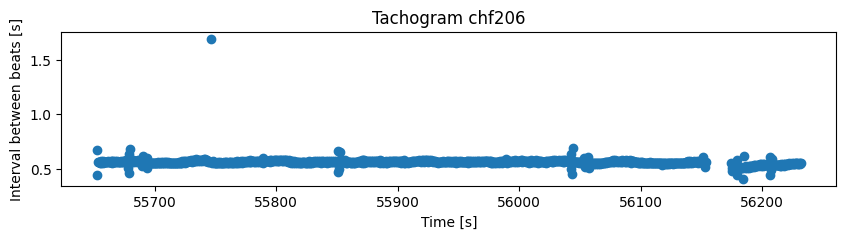

In [14]:
plt.figure(figsize=(10, 2))
fragment_s = 101097
fragment_len = 1000
plt.scatter(RR_chf_t[fragment_s:fragment_s+fragment_len], RR_chf[fragment_s:fragment_s+fragment_len])
plt.xlabel("Time [s]")
plt.ylabel("Interval between beats [s]")
plt.title("Tachogram chf206")
plt.show()

[0.0594019  0.46675039]
[1.87907672e-05 5.81931677e-01]
[-0.00136315  0.58812435]
[-5.84007968e-17  5.78000000e-01]


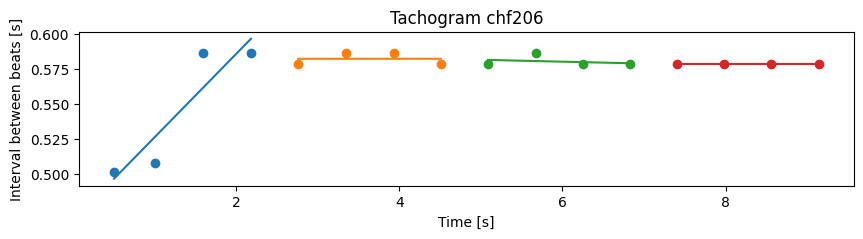

In [23]:
n = 4

plt.figure(figsize=(10, 2))

for i in range(0, 4*n, n):
    x, y = RR_chf_t[i:i + n], RR_chf[i:i + n]
    b = np.polyfit(x, y, 1)
    print(b)
    plt.scatter(x, y)

    lx = x[[0,-1]]
    ly = b[0]*lx + b[1]
    plt.plot(lx, ly)


plt.xlabel("Time [s]")
plt.ylabel("Interval between beats [s]")
plt.title("Tachogram chf206")
plt.show()

[0.01887447 0.51683992]


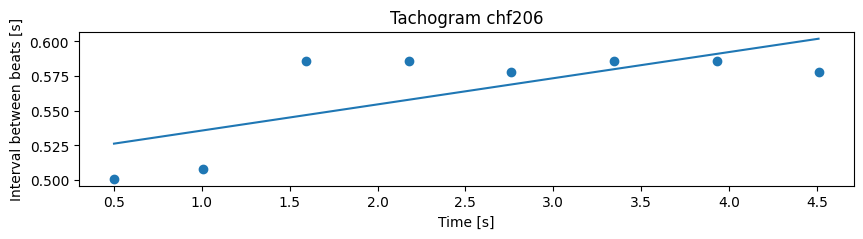

In [22]:
n = 4

plt.figure(figsize=(10, 2))

i = 0
n = 8
x, y = RR_chf_t[i:i + n], RR_chf[i:i + n]
b = np.polyfit(x, y, 1)
print(b)
plt.scatter(x, y)

lx = x[[0,-1]]
ly = b[0]*lx + b[1]
plt.plot(lx, ly)

plt.xlabel("Time [s]")
plt.ylabel("Interval between beats [s]")
plt.title("Tachogram chf206")
plt.show()